# Q1. What drives late deliveries?

**Decision it informs:** which shipping modes and regions need an SLA fix or a new promised date.

**Scope:** valid order items (cancelled and suspected-fraud excluded) in the analysis window,
January 2015 to September 2017. *Late* means actual shipping days > scheduled days
(`docs/kpi_definitions.md`). Every table below comes from a query in `sql/analysis/`.

**Method:** late rate by mode, region and category, the promised vs actual days gap,
chi-square tests with Cramér's V for every candidate driver, then a logistic regression
for the drivers' joint effect. Findings are associations, not causes.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from IPython.display import Markdown, display

from scdd.db import connect, q, run_analysis
from scdd import style
from scdd.stats import wilson_ci, two_prop_test, cramers_v, save_findings

style.apply()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
con = connect()

items = q("""
    SELECT f.order_item_id, f.order_id, f.customer_key, f.order_date, f.is_late, f.actual_days,
           f.scheduled_days, s.shipping_mode, s.payment_type, g.market, g.order_region,
           p.category_name, p.department_name, c.segment, d.weekday_name, d.year_month
    FROM fact_order_items f
    JOIN dim_shipping s USING (shipping_key)
    JOIN dim_geography g USING (geo_key)
    JOIN dim_product p USING (product_key)
    JOIN dim_customer c USING (customer_key)
    JOIN dim_date d ON d.date_key = f.order_date_key
    WHERE f.is_valid_order AND d.in_analysis_window
""", con)
print(f"{len(items):,} valid order items in the window; overall late rate {items.is_late.mean():.1%}")

164,572 valid order items in the window; overall late rate 57.3%


## 1. Late rate by shipping mode
Source: `sql/analysis/p2_late_by_mode.sql`. Intervals are 95% Wilson intervals.

In [2]:
by_mode = run_analysis("p2_late_by_mode.sql", con)
cis = [wilson_ci(r.late_rate * r.order_items, r.order_items) for r in by_mode.itertuples()]
by_mode["late_ci_low"], by_mode["late_ci_high"] = zip(*cis)
by_mode[["shipping_mode", "promised_days", "order_items", "late_rate", "late_ci_low", "late_ci_high",
         "avg_actual_days", "min_actual_days", "max_actual_days", "avg_delay_days_late_items"]]

,shipping_mode,promised_days,order_items,late_rate,late_ci_low,late_ci_high,avg_actual_days,min_actual_days,max_actual_days,avg_delay_days_late_items
0,Same Day,0,8851,0.4771,0.4667,0.4875,0.4771,0,1,1.0000
1,First Class,1,25270,1.0000,0.9998,1.0000,2.0000,2,2,1.0000
2,Second Class,2,32188,0.7981,0.7936,0.8024,3.9921,2,6,2.4962
3,Standard Class,4,98263,0.3978,0.3947,0.4008,3.9939,2,6,1.5069


## 2. Promised vs actual days
Source: `sql/analysis/p2_actual_days_distribution.sql`. The late rate is set by the gap between what each
mode promises and the days it actually takes.

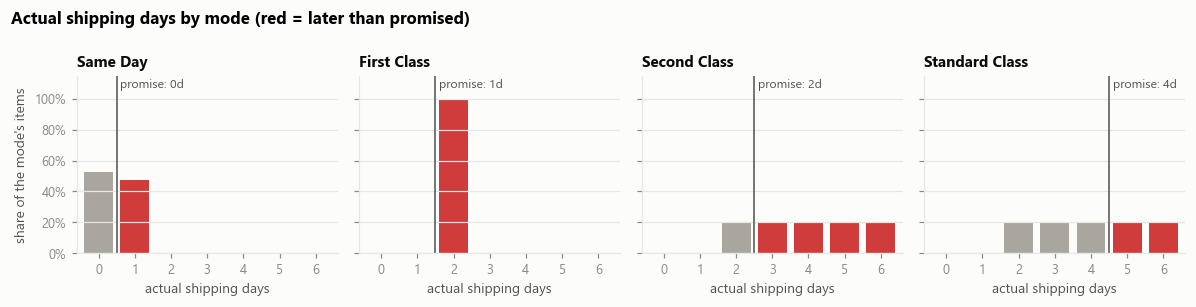

In [3]:
dist = run_analysis("p2_actual_days_distribution.sql", con)
modes = ["Same Day", "First Class", "Second Class", "Standard Class"]
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True)
for ax, m in zip(axes, modes):
    d = dist[dist.shipping_mode == m]
    promised = int(d.promised_days.iloc[0])
    colors = [style.BAD if a > promised else style.GREY for a in d.actual_days]
    ax.bar(d.actual_days, d.share_of_mode, color=colors, width=0.8)
    ax.axvline(promised + 0.5, color=style.INK_2, lw=1)
    ax.text(promised + 0.6, 1.13, f"promise: {promised}d", fontsize=8, color=style.INK_2, va="top")
    ax.set_title(m, fontsize=10)
    ax.set_xticks(range(0, 7)); ax.set_xlim(-0.6, 6.6); ax.set_ylim(0, 1.15)
    ax.set_xlabel("actual shipping days")
    style.pct(ax)
axes[0].set_ylabel("share of the mode's items")
fig.suptitle("Actual shipping days by mode (red = later than promised)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
style.save(fig, "q1_promised_vs_actual")
plt.show()

In [4]:
sec = items.loc[items.shipping_mode == "Second Class", "actual_days"]
std = items.loc[items.shipping_mode == "Standard Class", "actual_days"]
t_sec_std = stats.ttest_ind(sec, std, equal_var=False)
ct_days = pd.crosstab(items.loc[items.shipping_mode.isin(["Second Class", "Standard Class"]), "shipping_mode"],
                      items.loc[items.shipping_mode.isin(["Second Class", "Standard Class"]), "actual_days"])
chi_days = stats.chi2_contingency(ct_days)
print(f"Second Class mean actual days {sec.mean():.3f} vs Standard Class {std.mean():.3f}; "
      f"Welch t p = {t_sec_std.pvalue:.3f}; distribution chi-square p = {chi_days[1]:.3f}")

Second Class mean actual days 3.992 vs Standard Class 3.994; Welch t p = 0.846; distribution chi-square p = 0.431


## 3. Which factors are associated with lateness?
Chi-square test of independence between each factor and `is_late`, with Cramér's V as the effect size
(0 = no association, 1 = perfect). With 165k rows almost anything is "significant", so rank by V.

In [5]:
factors = {"shipping_mode": "Shipping mode", "order_region": "Order region", "market": "Market",
           "category_name": "Category", "department_name": "Department", "segment": "Customer segment",
           "payment_type": "Payment type", "weekday_name": "Order weekday"}
rows = []
for col, label in factors.items():
    ct = pd.crosstab(items[col], items.is_late)
    chi2, p, v = cramers_v(ct)
    rates = items.groupby(col).is_late.mean()
    rows.append({"factor": label, "levels": items[col].nunique(), "chi2": chi2, "p_value": p, "cramers_v": v,
                 "lowest_late_rate": rates.min(), "highest_late_rate": rates.max()})
drivers = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
drivers

,factor,levels,chi2,p_value,cramers_v,lowest_late_rate,highest_late_rate
0,Shipping mode,4,"38,153.4430",0.0000,0.4815,0.3978,1.0000
1,Order region,23,76.1489,0.0000,0.0215,0.5160,0.6015
2,Category,32,30.7278,0.4800,0.0137,0.4927,0.6885
3,Order weekday,7,13.0589,0.0421,0.0089,0.5655,0.5793
4,Market,5,8.6706,0.0699,0.0073,0.5684,0.5776
5,Payment type,4,7.4223,0.0596,0.0067,0.5659,0.5764
6,Department,6,2.3164,0.8039,0.0038,0.5720,0.5800
7,Customer segment,3,1.4319,0.4887,0.0029,0.5708,0.5749


Market rotates with calendar time in this dataset (see the data-quality log), so a market effect could be a
period effect. Test market *within* each shipping mode:

In [6]:
within = []
for m in modes:
    sub = items[items.shipping_mode == m]
    if sub.is_late.nunique() < 2:
        within.append({"shipping_mode": m, "p_value": np.nan, "cramers_v": 0.0, "note": "late on every item"})
        continue
    chi2, p, v = cramers_v(pd.crosstab(sub.market, sub.is_late))
    rates = sub.groupby("market").is_late.mean()
    within.append({"shipping_mode": m, "p_value": p, "cramers_v": v,
                   "note": f"market late rates {rates.min():.1%} to {rates.max():.1%}"})
pd.DataFrame(within)

,shipping_mode,p_value,cramers_v,note
0,Same Day,0.0002,0.0494,market late rates 43.8% to 50.4%
1,First Class,NaN,0.0000,late on every item
2,Second Class,0.2080,0.0135,market late rates 79.1% to 80.4%
3,Standard Class,0.8731,0.0035,market late rates 39.5% to 40.0%


## 4. Mode x region heatmap
Source: `sql/analysis/p2_mode_region_heatmap.sql` (cells with at least 200 items).

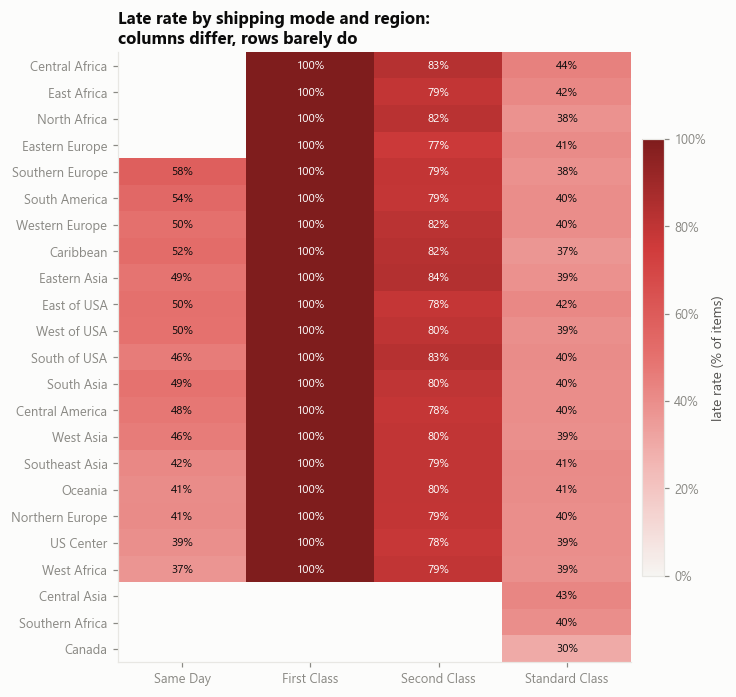

,min,max
shipping_mode,,
First Class,1.0000,1.0000
Same Day,0.3726,0.5787
Second Class,0.7656,0.8363
Standard Class,0.2996,0.4432


In [7]:
hm = run_analysis("p2_mode_region_heatmap.sql", con)
piv = hm.pivot(index="order_region", columns="shipping_mode", values="late_rate")[modes]
piv = piv.loc[piv.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(6.4, 7.2))
im = ax.imshow(piv.values, cmap=style.BAD_RAMP, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(modes)), modes, rotation=0, fontsize=8.5)
ax.set_yticks(range(len(piv)), piv.index, fontsize=8.5)
ax.grid(False)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7.5,
                    color="white" if v > 0.6 else style.INK)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, format=plt.matplotlib.ticker.PercentFormatter(1.0))
cb.set_label("late rate (% of items)")
ax.set_title("Late rate by shipping mode and region:\ncolumns differ, rows barely do")
style.save(fig, "q1_mode_region_heatmap")
plt.show()
region_spread = hm.groupby("shipping_mode").late_rate.agg(["min", "max"])
region_spread

## 5. Logistic regression
First Class is late on 100% of items, which a logit cannot fit (perfect separation), so it is reported above and
left out here. For the other three modes, the drop-one likelihood-ratio test says how much each factor adds once
the others are in the model.

In [8]:
lr_data = items[items.shipping_mode != "First Class"].copy()
lr_data["is_late"] = lr_data.is_late.astype(int)
terms = {"mode": "C(shipping_mode)", "market": "C(market)", "department": "C(department_name)",
         "segment": "C(segment)", "payment": "C(payment_type)", "weekday": "C(weekday_name)"}
full = smf.logit("is_late ~ " + " + ".join(terms.values()), lr_data).fit(disp=0)
lr_rows = []
for name, term in terms.items():
    reduced = smf.logit("is_late ~ " + " + ".join(t for t in terms.values() if t != term), lr_data).fit(disp=0)
    lr_stat = 2 * (full.llf - reduced.llf)
    df_diff = full.df_model - reduced.df_model
    lr_rows.append({"factor": name, "lr_chi2": lr_stat, "df": df_diff, "p_value": stats.chi2.sf(lr_stat, df_diff)})
lr_table = pd.DataFrame(lr_rows).sort_values("lr_chi2", ascending=False).reset_index(drop=True)
print(f"pseudo R-squared, full model: {full.prsquared:.3f}")
odds = np.exp(full.params.filter(like="shipping_mode")).rename("odds_ratio_vs_Same_Day")
display(odds.to_frame())
lr_table

pseudo R-squared, full model: 0.085


,odds_ratio_vs_Same_Day
C(shipping_mode)[T.Second Class],4.3315
C(shipping_mode)[T.Standard Class],0.7236


,factor,lr_chi2,df,p_value
0,mode,"16,377.7493",2.0000,0.0000
1,weekday,12.0104,6.0000,0.0617
2,payment,9.8827,3.0000,0.0196
3,department,4.4698,5.0000,0.4839
4,segment,2.8978,2.0000,0.2348
5,market,1.5548,4.0000,0.8169


In [9]:
mode_only = smf.logit("is_late ~ C(shipping_mode)", lr_data).fit(disp=0)
print(f"pseudo R-squared, shipping mode alone: {mode_only.prsquared:.3f} (full model {full.prsquared:.3f})")

pseudo R-squared, shipping mode alone: 0.085 (full model 0.085)


## 6. Does lateness cost repeat business?
If late deliveries drove customers away, a late *first* order should lower the chance of ordering again.
Customers whose first valid order is before July 2017 (so 90 days of follow-up fit in the window):

In [10]:
first = q("""
    WITH o AS (
        SELECT customer_key, order_id, min(order_date) AS d, bool_or(is_late) AS late
        FROM fact_order_items
        WHERE is_valid_order AND order_date < DATE '2017-10-01'
        GROUP BY 1, 2
    ), r AS (
        SELECT *, row_number() OVER (PARTITION BY customer_key ORDER BY d, order_id) AS rn FROM o
    )
    SELECT a.customer_key, a.late AS first_order_late,
           EXISTS (SELECT 1 FROM o b WHERE b.customer_key = a.customer_key
                   AND b.d > a.d AND b.d <= a.d + INTERVAL 90 DAY) AS reordered_90d
    FROM r a
    WHERE a.rn = 1 AND a.d < DATE '2017-07-01'
""", con)
g = first.groupby("first_order_late").reordered_90d.agg(["sum", "count", "mean"])
repeat_test = two_prop_test(g.loc[True, "sum"], g.loc[True, "count"], g.loc[False, "sum"], g.loc[False, "count"])
display(g)
print(f"Reorder within 90 days: {repeat_test['p1']:.1%} after a late first order vs {repeat_test['p2']:.1%} after "
      f"an on-time one; difference {repeat_test['diff'] * 100:+.1f} pts "
      f"(95% CI {repeat_test['ci_low'] * 100:+.1f} to {repeat_test['ci_high'] * 100:+.1f}), p = {repeat_test['p_value']:.2f}")

,sum,count,mean
first_order_late,,,
False,1722,5258,0.3275
True,2287,6966,0.3283


Reorder within 90 days: 32.8% after a late first order vs 32.8% after an on-time one; difference +0.1 pts (95% CI -1.6 to +1.8), p = 0.92


## 7. What if the promises matched reality?
Source: `sql/analysis/p2_repromise_whatif.sql`. Holds actual days as observed and changes only the promise.

In [11]:
whatif = run_analysis("p2_repromise_whatif.sql", con)
whatif

,scenario,late_rate
0,current promise,0.5728
1,First Class promised 2 days,0.4193
2,First Class 2 days + Second Class 4 days,0.3410


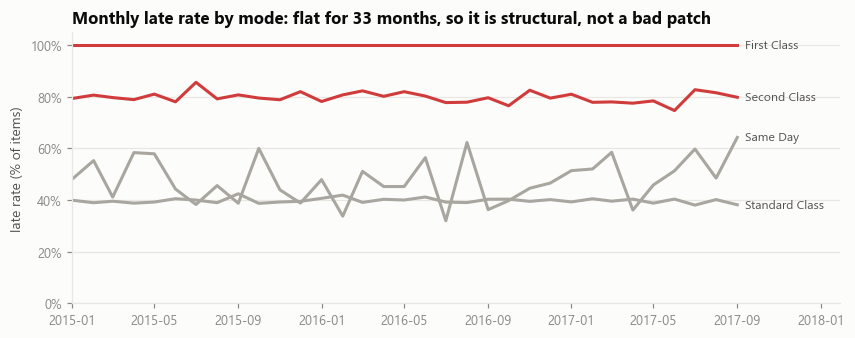

In [12]:
trend = run_analysis("p2_late_trend.sql", con)
fig, ax = plt.subplots(figsize=(9, 3.2))
for m in modes:
    d = trend[trend.shipping_mode == m]
    color = style.BAD if m in ("First Class", "Second Class") else style.GREY
    ax.plot(d.month_start, d.late_rate, color=color, lw=2)
    ax.text(d.month_start.iloc[-1] + pd.Timedelta(days=12), d.late_rate.iloc[-1], m, fontsize=8, va="center",
            color=style.INK_2)
ax.set_ylim(0, 1.05); style.pct(ax)
ax.set_ylabel("late rate (% of items)")
ax.set_title("Monthly late rate by mode: flat for 33 months, so it is structural, not a bad patch")
ax.set_xlim(trend.month_start.min(), trend.month_start.max() + pd.Timedelta(days=150))
style.save(fig, "q1_late_trend")
plt.show()

## Finding → number → decision

In [13]:
fc = by_mode.set_index("shipping_mode")
mode_v = drivers.loc[drivers.factor == "Shipping mode", "cramers_v"].iloc[0]
next_v = drivers.loc[drivers.factor != "Shipping mode", "cramers_v"].max()
next_factor = drivers.loc[drivers.factor != "Shipping mode"].sort_values("cramers_v").iloc[-1].factor
w = whatif.set_index("scenario").late_rate
findings = {
    "overall_late_rate": items.is_late.mean(),
    "valid_items": len(items),
    "late_rate_by_mode": fc.late_rate.to_dict(),
    "late_ci_by_mode": {m: [fc.loc[m, "late_ci_low"], fc.loc[m, "late_ci_high"]] for m in fc.index},
    "items_by_mode": fc.order_items.to_dict(),
    "promised_days_by_mode": fc.promised_days.to_dict(),
    "avg_actual_days_by_mode": fc.avg_actual_days.to_dict(),
    "second_vs_standard_actual_days_p": t_sec_std.pvalue,
    "cramers_v_mode": mode_v,
    "cramers_v_next_best": next_v,
    "next_best_factor": next_factor,
    "pseudo_r2_full": full.prsquared,
    "pseudo_r2_mode_only": mode_only.prsquared,
    "reorder_90d_after_late": repeat_test["p1"],
    "reorder_90d_after_on_time": repeat_test["p2"],
    "reorder_diff_ci": [repeat_test["ci_low"], repeat_test["ci_high"]],
    "reorder_p_value": repeat_test["p_value"],
    "late_rate_current": w["current promise"],
    "late_rate_first_class_2d": w["First Class promised 2 days"],
    "late_rate_first2_second4": w["First Class 2 days + Second Class 4 days"],
}
save_findings("q1", findings)
display(Markdown(f"""
**Finding.** Lateness is set by the shipping mode's promise, not by geography or product. First Class is late on
**{fc.loc['First Class', 'late_rate']:.0%}** of items (it always takes 2 days against a 1-day promise) and Second Class on
**{fc.loc['Second Class', 'late_rate']:.1%}** (it takes {fc.loc['Second Class', 'avg_actual_days']:.2f} days on average, the same as
Standard Class's {fc.loc['Standard Class', 'avg_actual_days']:.2f}, p = {t_sec_std.pvalue:.2f}), vs **{fc.loc['Standard Class', 'late_rate']:.1%}** for Standard Class.
Shipping mode has Cramér's V = {mode_v:.2f}; the next factor ({next_factor.lower()}) has {next_v:.3f}.

**Number.** Re-promising First Class at 2 days and Second Class at 4 days, with no change to how fast anything ships,
takes the overall late rate from **{w['current promise']:.1%} to {w['First Class 2 days + Second Class 4 days']:.1%}**.
Late first orders are not associated with fewer repeat orders ({repeat_test['p1']:.1%} vs {repeat_test['p2']:.1%} reorder within 90 days,
p = {repeat_test['p_value']:.2f}), so the case is about keeping promises, not recovering lost revenue.

**Decision.** Fix the promise per *mode*, not per region: change First Class to a 2-day promise, and either make
Second Class faster than Standard or re-promise it at 4 days. No region needs a region-specific SLA fix.
"""))


**Finding.** Lateness is set by the shipping mode's promise, not by geography or product. First Class is late on
**100%** of items (it always takes 2 days against a 1-day promise) and Second Class on
**79.8%** (it takes 3.99 days on average, the same as
Standard Class's 3.99, p = 0.85), vs **39.8%** for Standard Class.
Shipping mode has Cramér's V = 0.48; the next factor (order region) has 0.022.

**Number.** Re-promising First Class at 2 days and Second Class at 4 days, with no change to how fast anything ships,
takes the overall late rate from **57.3% to 34.1%**.
Late first orders are not associated with fewer repeat orders (32.8% vs 32.8% reorder within 90 days,
p = 0.92), so the case is about keeping promises, not recovering lost revenue.

**Decision.** Fix the promise per *mode*, not per region: change First Class to a 2-day promise, and either make
Second Class faster than Standard or re-promise it at 4 days. No region needs a region-specific SLA fix.
